# 🔤 01 · Text to Numbers: One-Hot Encoding and TF-IDF

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 1 of 9
> Course notes: page 8, *"How to convert text to numbers? … One-hot, TF-IDF … 1-hot encoding: distance between nice & good same as nice & bad. All equidistant. Cannot capture meaning"* and page 9 ($TF(w_i,d_j)$, $IDF(w_i,D)$)

Every network in modules 01–02 eats **numbers**. Text is not numbers. Before we can build word2vec, RNNs or GPT, we need a way to turn words and documents into vectors – and the *kind* of vector we choose decides what the network can possibly learn.

This notebook tries the three simplest ideas, in the order the notes discuss them, and finds out exactly what each one gets wrong:

| # | Idea | What goes wrong |
|---|---|---|
| 1 | Store the characters (like a hard disk does) | different lengths; spelling ≠ meaning |
| 2 | **One-hot** vectors | every word is equally far from every other word |
| 3 | **TF-IDF** document vectors | better: words get described by *where* they appear, but vectors are huge and ignore word order |

That last observation – *describe a word by where it appears* – is the seed of everything in this module.

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
from collections import Counter

---
## 1 · The variables 📖

| Symbol | Meaning | Example |
|---|---|---|
| token | one word after splitting a sentence | `"bank"` |
| vocabulary | the list of all different tokens we have seen | `["bank", "fish", ...]` |
| $n$ | vocabulary size | 30 |
| $w_i$ | the $i$-th word of the vocabulary | $w_3=$ `"bank"` |
| $x^{(w)}$ | one-hot vector of word $w$: length $n$, a single 1 at the word's index | $(0,0,1,0,\dots)$ |
| $D=\lbrace d_1,\dots,d_m\rbrace$ | a collection (**corpus**) of $m$ documents | 6 short documents |
| $\text{count}(w,d)$ | how many times $w$ occurs in document $d$ | 2 |
| $\lvert d\rvert$ | length of document $d$ (number of tokens) | 7 |
| $TF(w,d)$ | **term frequency**: how important $w$ is *inside* $d$ | $2/7$ |
| $df(w)$ | **document frequency**: in how many documents $w$ appears | 3 |
| $IDF(w,D)$ | **inverse document frequency**: how *rare* (informative) $w$ is across the corpus | – |
| $\cos(a,b)$ | cosine similarity $=\dfrac{a\cdot b}{\lVert a\rVert\ \lVert b\rVert}$: 1 = same direction, 0 = unrelated | – |

---
## 2 · Idea 1: store the characters 💾

The notes' first thought: *"Store each char individually like a hard disk."* Each character becomes its byte code (`'a'` = 97, …). Problem 1 is immediately visible: words have **different lengths**, but a network layer needs a **fixed** input size.

In [2]:
words = ["i", "like", "going", "to", "my", "old", "house"]    # the sentence from the notes
codes = {w: list(w.encode("ascii")) for w in words}            # each character → its byte value
for w, c in codes.items():
    print(f"{w:<6} → {c}   ({len(c)} numbers)")

i      → [105]   (1 numbers)
like   → [108, 105, 107, 101]   (4 numbers)
going  → [103, 111, 105, 110, 103]   (5 numbers)
to     → [116, 111]   (2 numbers)
my     → [109, 121]   (2 numbers)
old    → [111, 108, 100]   (3 numbers)
house  → [104, 111, 117, 115, 101]   (5 numbers)


**The fix in the notes:** *"Take longest input, rest pad with 0s."* Every word becomes a vector of the same length $L_{max}$ by appending zeros.

In [3]:
def char_vector(word, length):
    """Byte codes of the word, padded with zeros up to `length`."""
    c = list(word.encode("ascii"))
    return np.array(c + [0] * (length - len(c)), dtype=float)

L_max = max(len(w) for w in words)
X_chars = np.array([char_vector(w, L_max) for w in words])
print("padded length =", L_max, "\n", X_chars.astype(int))

padded length = 5 
 [[105   0   0   0   0]
 [108 105 107 101   0]
 [103 111 105 110 103]
 [116 111   0   0   0]
 [109 121   0   0   0]
 [111 108 100   0   0]
 [104 111 117 115 101]]


Two new problems:
* *"New longer word → need to change architecture again"* (notes). `"neighbourhood"` does not fit in 5 slots.
* **Spelling is not meaning.** Let us measure distances between a few words in this character space.

In [4]:
probe = ["nice", "mice", "good", "great", "bad", "awful"]
L_p = max(map(len, probe))
P = np.array([char_vector(w, L_p) for w in probe])
dist_chars = np.linalg.norm(P[:, None, :] - P[None, :, :], axis=-1)   # all pairwise Euclidean distances
print(f"distance(nice, mice) = {dist_chars[0, 1]:.1f}   ← closest pair, but unrelated meanings")
print(f"distance(nice, good) = {dist_chars[0, 2]:.1f}")
print(f"distance(nice, bad)  = {dist_chars[0, 4]:.1f}")

distance(nice, mice) = 1.0   ← closest pair, but unrelated meanings
distance(nice, good) = 15.2
distance(nice, bad)  = 102.0


📊 **Plot:** all pairwise distances. In character space `nice` is closest to `mice` – the representation knows nothing about meaning.

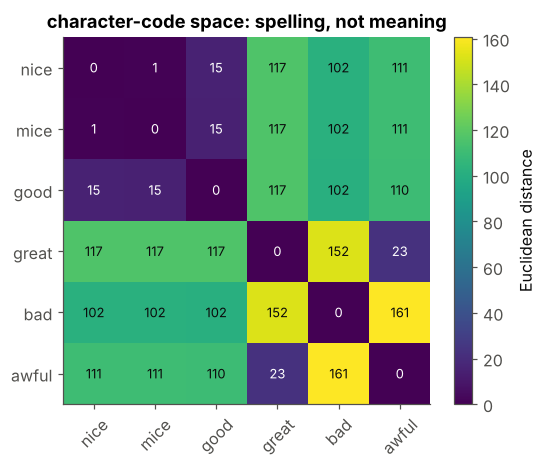

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.3))
im = ax.imshow(dist_chars, cmap="viridis")
ax.set_xticks(range(len(probe)), probe, rotation=45); ax.set_yticks(range(len(probe)), probe)
for (i, j), v in np.ndenumerate(dist_chars):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v < dist_chars.max() / 2 else C["ink"])
plt.colorbar(im, ax=ax, label="Euclidean distance")
ax.set_title("character-code space: spelling, not meaning"); ax.grid(False)
plt.tight_layout(); plt.show()

---
## 3 · A small corpus to work with 📚

Six tiny documents: two about **money**, two about a **river**, and two everyday sentences. The word **"bank"** appears in both the money and the river documents – remember it.

In [6]:
docs = [
    "the bank gave me a loan with low interest",
    "i pay interest on my bank loan every month",
    "fish swim near the bank of the river",
    "the river water flows past the bank",
    "i like going to my old house",
    "the food is nice and the room is good",
]
print(len(docs), "documents")

6 documents


**Tokenise and build the vocabulary.** Tokenising here just means lower-casing and splitting on spaces (real systems also handle punctuation, sub-words, …). The vocabulary is the sorted list of distinct tokens; `index` maps each word to its position $i$.

In [7]:
tokens = [d.lower().split() for d in docs]              # list of token lists
vocab = sorted({w for t in tokens for w in t})           # distinct words, alphabetical
index = {w: i for i, w in enumerate(vocab)}              # word → position i
n = len(vocab)
print(f"n = {n} distinct words:\n{vocab}")

n = 34 distinct words:
['a', 'and', 'bank', 'every', 'fish', 'flows', 'food', 'gave', 'going', 'good', 'house', 'i', 'interest', 'is', 'like', 'loan', 'low', 'me', 'month', 'my', 'near', 'nice', 'of', 'old', 'on', 'past', 'pay', 'river', 'room', 'swim', 'the', 'to', 'water', 'with']


---
## 4 · Idea 2: one-hot vectors 🔦

Each word $w_i$ becomes a vector of length $n$ that is **0 everywhere except a 1 at position $i$**:

$$x^{(w_i)}=(0,\dots,0,\underbrace{1}_{\text{position }i},0,\dots,0)$$

It is the simplest possible code: no information about the word except *which word it is*. We build it as a tiny class in two cells.

### 4.1 · Fitting = remembering the vocabulary
`fit` only stores the word list and its index map. There is nothing to "learn" – that is exactly the weakness we are about to measure.

In [8]:
class OneHotEncoder:
    """Turns words into one-hot vectors of length n (the vocabulary size)."""

    def fit(self, token_lists):
        self.vocab = sorted({w for t in token_lists for w in t})
        self.index = {w: i for i, w in enumerate(self.vocab)}
        self.n = len(self.vocab)
        return self

### 4.2 · Transforming a word
Create a zero vector of length $n$ and put a 1 at the word's index. A word never seen during `fit` raises an error – one-hot vectors cannot represent new words (another weakness).

In [9]:
def transform(self, word):
    x = np.zeros(self.n)
    x[self.index[word]] = 1.0          # the single 1
    return x

OneHotEncoder.transform = transform

enc = OneHotEncoder().fit(tokens)
print("x(bank) =", enc.transform("bank").astype(int))
print("x(loan) =", enc.transform("loan").astype(int))

x(bank) = [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
x(loan) = [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### 4.3 · Measuring meaning: every pair is equally far apart
For two **different** words, the vectors have their 1s in different places, so

$$\lVert x^{(a)}-x^{(b)}\rVert=\sqrt{1^2+1^2}=\sqrt2\approx1.414,\qquad x^{(a)}\cdot x^{(b)}=0\ \Rightarrow\ \cos=0.$$

No matter which two words we pick. The notes: *"distance between nice & good same as nice & bad. All equidistant. Cannot capture meaning."*

In [10]:
probe = ["nice", "good", "loan", "interest", "river", "fish"]
Xp = np.array([enc.transform(w) for w in probe])
dist_onehot = np.linalg.norm(Xp[:, None, :] - Xp[None, :, :], axis=-1)
cos_onehot = Xp @ Xp.T                                  # vectors have length 1, so dot = cosine
print("distance(nice, good) =", dist_onehot[0, 1].round(3), "  distance(nice, river) =", dist_onehot[0, 4].round(3))
print("cosine  (nice, good) =", cos_onehot[0, 1], "     cosine  (nice, river) =", cos_onehot[0, 4])

distance(nice, good) = 1.414   distance(nice, river) = 1.414
cosine  (nice, good) = 0.0      cosine  (nice, river) = 0.0


📊 **Plot:** distances (left) and cosine similarities (right) between six words. Every off-diagonal cell is identical.

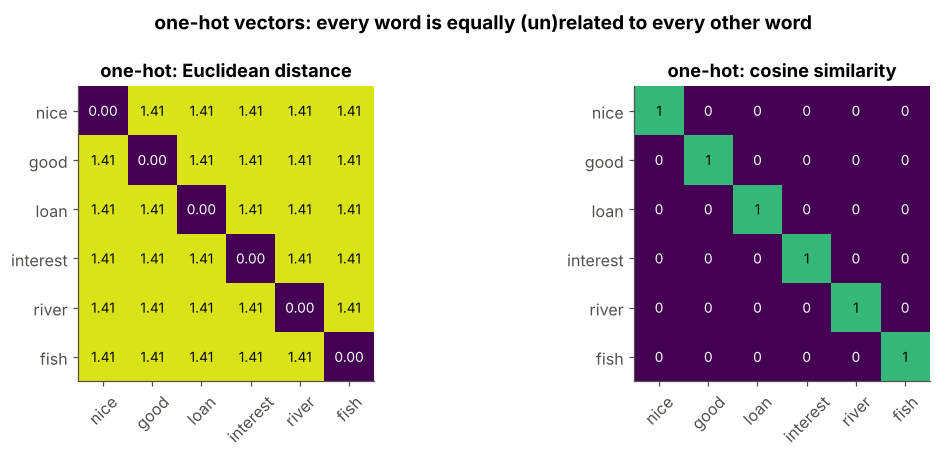

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, M, title, fmt in [(axs[0], dist_onehot, "one-hot: Euclidean distance", "{:.2f}"),
                          (axs[1], cos_onehot, "one-hot: cosine similarity", "{:.0f}")]:
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=max(1.5, M.max()))
    ax.set_xticks(range(len(probe)), probe, rotation=45); ax.set_yticks(range(len(probe)), probe)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if v < 0.75 else C["ink"])
    ax.set_title(title); ax.grid(False)
fig.suptitle("one-hot vectors: every word is equally (un)related to every other word", fontweight="bold")
plt.tight_layout(); plt.show()

Also: the vector length grows with the vocabulary ($n\approx10^5$ for English) while carrying just one bit of useful information.

---
## 5 · From words to documents: bag of words 👜

A document can be turned into a vector by **adding up the one-hot vectors of its words**. Entry $i$ is then $\text{count}(w_i,d)$. Stacking the document vectors as columns gives the **term–document matrix** ($n$ words × $m$ documents).

In [12]:
def count_matrix(token_lists, index):
    """C[i, j] = how many times word i occurs in document j."""
    Cm = np.zeros((len(index), len(token_lists)))
    for j, toks in enumerate(token_lists):
        for w, c in Counter(toks).items():          # Counter counts each word in the document
            Cm[index[w], j] = c
    return Cm

counts = count_matrix(tokens, index)
print("term-document matrix:", counts.shape, "(words × documents)")
print("column for document 1 (non-zero entries):", {vocab[i]: int(c) for i, c in enumerate(counts[:, 1]) if c})

term-document matrix: (34, 6) (words × documents)
column for document 1 (non-zero entries): {'bank': 1, 'every': 1, 'i': 1, 'interest': 1, 'loan': 1, 'month': 1, 'my': 1, 'on': 1, 'pay': 1}


---
## 6 · Idea 3: TF-IDF 📊

Raw counts favour frequent but meaningless words such as *"the"*. TF-IDF multiplies two factors:

**Term frequency** – how important $w$ is *within* document $d$ (notes, page 9):

$$TF(w,d)=\frac{\text{count}(w,d)}{\lvert d\rvert}$$

**Inverse document frequency** – how *rare* $w$ is across the corpus. The notes write the simplest form, $IDF(w,D)=\dfrac{1}{df(w)}$; the version used in practice takes a logarithm so that the effect is gentler:

$$IDF_{\text{notes}}(w,D)=\frac{1}{df(w)},\qquad IDF(w,D)=\log\frac{m}{df(w)}$$

$$\boxed{TFIDF(w,d)=TF(w,d)\times IDF(w,D)}$$

**Intuition:** a word scores high in a document if it is **frequent there** but **rare elsewhere** – exactly the words that tell you what the document is about. A word in every document gets $\log(m/m)=0$.

### 6.1 · Term frequency
Divide each column of the count matrix by that document's length. `counts.sum(axis=0)` gives the lengths; broadcasting divides every column by its own length.

In [13]:
doc_len = counts.sum(axis=0)                 # |d_j| for every document
TF = counts / doc_len                        # TF(w, d) = count / length
print("document lengths:", doc_len.astype(int))
print("TF(interest, doc 1) =", TF[index["interest"], 1].round(3), "= 1 /", int(doc_len[1]))

document lengths: [9 9 8 7 7 9]
TF(interest, doc 1) = 0.111 = 1 / 9


### 6.2 · Document frequency and IDF
`(counts > 0).sum(axis=1)` counts, for every word, the documents in which it appears at least once. We compute both IDF versions to compare them.

In [14]:
m = len(docs)
df = (counts > 0).sum(axis=1)                # df(w): number of documents containing w
IDF_notes = 1.0 / df                         # notes' version
IDF = np.log(m / df)                         # standard version
for w in ["the", "bank", "interest", "fish"]:
    i = index[w]
    print(f"{w:<9} df = {df[i]}   IDF_notes = {IDF_notes[i]:.3f}   IDF = log({m}/{df[i]}) = {IDF[i]:.3f}")

the       df = 4   IDF_notes = 0.250   IDF = log(6/4) = 0.405
bank      df = 4   IDF_notes = 0.250   IDF = log(6/4) = 0.405
interest  df = 2   IDF_notes = 0.500   IDF = log(6/2) = 1.099
fish      df = 1   IDF_notes = 1.000   IDF = log(6/1) = 1.792


### 6.3 · Put them together
`IDF[:, None]` turns the IDF vector into a column so it multiplies every row (word) of the TF matrix.

In [15]:
TFIDF = TF * IDF[:, None]                    # TF-IDF(w, d) for every word and document
top = np.argsort(-TFIDF, axis=0)[:3]         # 3 highest-scoring words per document
for j in range(m):
    print(f"doc {j}: top words = {[vocab[i] for i in top[:, j]]}")

doc 0: top words = ['a', 'gave', 'me']
doc 1: top words = ['every', 'pay', 'on']
doc 2: top words = ['fish', 'swim', 'near']
doc 3: top words = ['flows', 'past', 'water']
doc 4: top words = ['house', 'like', 'going']
doc 5: top words = ['is', 'and', 'good']


Two effects are visible. `the` (in 4 of 6 documents) never makes a top list – its IDF is low. And the top words are the ones **unique to each document**: content words such as *fish, swim, water, house* – but in such a tiny corpus also fillers like *a* and *me*, because they happen to occur in only one document. In a real corpus with thousands of documents those fillers appear almost everywhere and their IDF drops to nearly 0.

📊 **Plot:** raw counts vs TF-IDF for every word (rows) and document (columns).

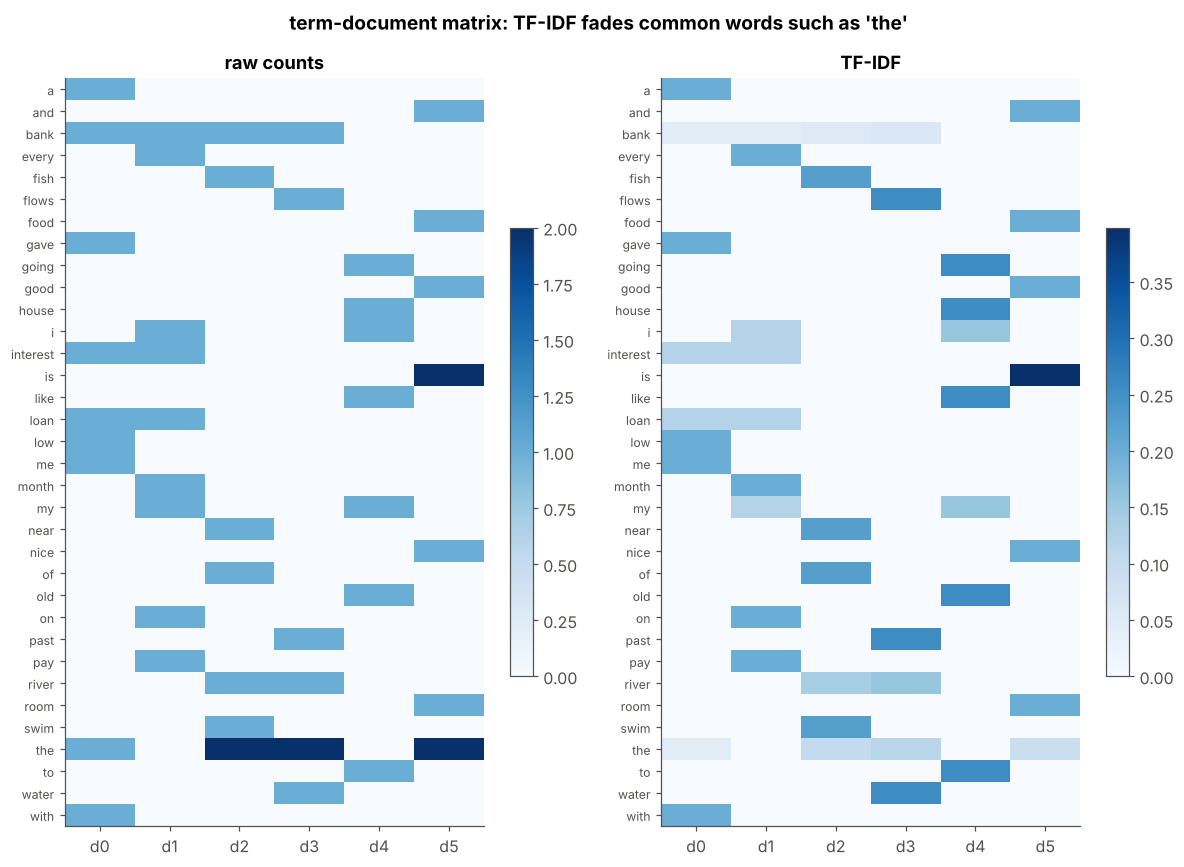

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 8))
for ax, M, title in [(axs[0], counts, "raw counts"), (axs[1], TFIDF, "TF-IDF")]:
    im = ax.imshow(M, cmap="Blues", aspect="auto")
    ax.set_yticks(range(n), vocab, fontsize=8); ax.set_xticks(range(m), [f"d{j}" for j in range(m)])
    ax.set_title(title); ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.6)
fig.suptitle("term-document matrix: TF-IDF fades common words such as 'the'", fontweight="bold")
plt.tight_layout(); plt.show()

---
## 7 · Reading the matrix the other way: words as vectors ↔️

So far the **columns** were document vectors. Now read the **rows**: row $i$ describes word $w_i$ by **which documents it appears in**. The notes: *"Words related to finance will have non-zero values in finance documents."*

That is a big step beyond one-hot: two words get **similar vectors if they appear in similar documents**.

In [17]:
W_vec = TFIDF.copy()                                             # one row per word, one column per document
norms = np.linalg.norm(W_vec, axis=1, keepdims=True)
W_unit = W_vec / np.where(norms == 0, 1, norms)                 # unit length, so dot product = cosine
cos_tfidf = W_unit @ W_unit.T

probe = ["loan", "interest", "bank", "river", "fish", "water", "nice", "good"]
pi = [index[w] for w in probe]
for a, b in [("loan", "interest"), ("river", "fish"), ("bank", "loan"), ("bank", "river"), ("loan", "fish")]:
    print(f"cos({a}, {b}) = {cos_tfidf[index[a], index[b]]:.2f}")

cos(loan, interest) = 1.00
cos(river, fish) = 0.66
cos(bank, loan) = 0.64
cos(bank, river) = 0.77
cos(loan, fish) = 0.00


📊 **Plot:** cosine similarity between word vectors taken from the TF-IDF rows. Money words cluster, river words cluster, and **"bank" is similar to both** – one vector has to serve two meanings.

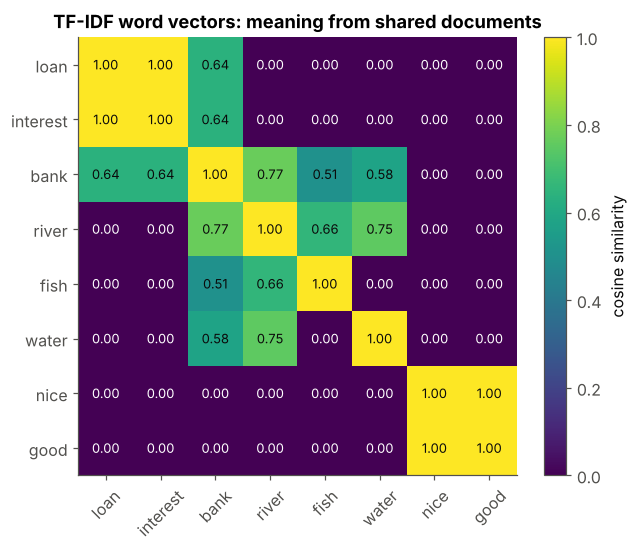

In [18]:
S = cos_tfidf[np.ix_(pi, pi)]
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(S, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(probe)), probe, rotation=45); ax.set_yticks(range(len(probe)), probe)
for (i, j), v in np.ndenumerate(S):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v < 0.5 else C["ink"])
plt.colorbar(im, ax=ax, label="cosine similarity"); ax.grid(False)
ax.set_title("TF-IDF word vectors: meaning from shared documents")
plt.tight_layout(); plt.show()

### A 2-D picture of the word vectors
Each word vector has $m=6$ numbers. To draw it we squash 6-D to 2-D with the **SVD** (the best 2-D linear projection, also called PCA): `np.linalg.svd` finds the two directions along which the word vectors vary most, and we keep the coordinates along them.

In [19]:
centered = W_unit - W_unit.mean(axis=0)
Usvd, Ssvd, _ = np.linalg.svd(centered, full_matrices=False)
coords = Usvd[:, :2] * Ssvd[:2]                                   # 2-D coordinates of every word
print(f"the first 2 directions keep {100 * (Ssvd[:2] ** 2).sum() / (Ssvd ** 2).sum():.0f}% of the variation")

the first 2 directions keep 49% of the variation


📊 **Plot:** every word placed by its 2-D coordinates and coloured by topic. Words that occur in exactly the same documents get identical vectors, so they land on the same spot; we group them under one label.

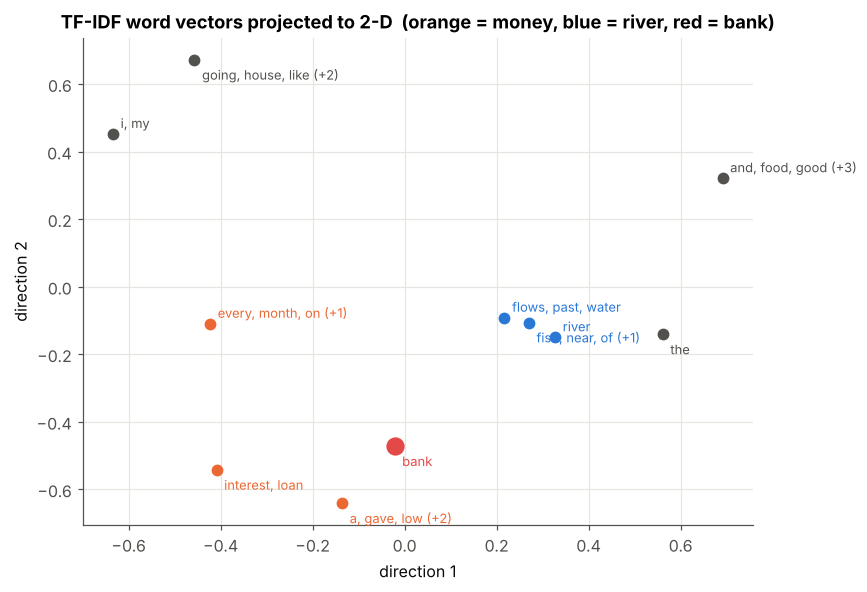

In [20]:
topic = {**{w: C["orange"] for w in ["loan", "interest", "pay", "month", "every", "gave", "low", "with", "me", "a"]},
         **{w: C["blue"] for w in ["river", "fish", "swim", "water", "flows", "past", "near", "of"]},
         "bank": C["red"]}
groups = {}                                                       # identical points → one label
for w, (x0, y0) in zip(vocab, coords):
    groups.setdefault((round(x0, 3), round(y0, 3)), []).append(w)
fig, ax = plt.subplots(figsize=(8, 5.5))
for g_i, ((x0, y0), ws) in enumerate(groups.items()):
    col = topic.get(ws[0], C["muted"])
    ax.scatter(x0, y0, color=col, s=120 if "bank" in ws else 45, zorder=3)
    label = ", ".join(ws) if len(ws) <= 3 else ", ".join(ws[:3]) + f" (+{len(ws) - 3})"
    ax.annotate(label, (x0, y0), textcoords="offset points", xytext=(5, 4 if g_i % 2 else -13), fontsize=8.5, color=col)
ax.set_title("TF-IDF word vectors projected to 2-D  (orange = money, blue = river, red = bank)")
ax.set_xlabel("direction 1"); ax.set_ylabel("direction 2")
plt.tight_layout(); plt.show()

---
## 8 · What TF-IDF still cannot do ⚠️

1. **Huge, sparse vectors.** A word vector has one entry per *document* (millions on the web), almost all zero.
2. **One vector per word.** "bank" (river) and "bank" (money) share a single vector – the notes call this the *word-to-vector limitation*.
3. **Word order is lost.** A document is a bag of words:

In [21]:
a = Counter("dog bites man".split())
b = Counter("man bites dog".split())
print("bag of words identical?", a == b, " → same vector, opposite meanings")

bag of words identical? True  → same vector, opposite meanings


4. **Dimensions mean "documents", not properties.** Column 3 of the matrix means "appears in document 3"; it does not mean anything like *royal* or *edible*.

The next notebook keeps the good idea (*describe a word by its surroundings*) but uses **neighbouring words** instead of whole documents – and then compresses the result into short, dense vectors.

---
## 9 · Summary 📌

| Representation | Vector length | Captures meaning? | Main problem |
|---|---|---|---|
| characters (padded) | longest word | ❌ spelling only | variable length; `nice` ≈ `mice` |
| one-hot | $n$ (vocabulary) | ❌ all words equidistant ($\sqrt2$) | no similarity at all |
| bag of words / TF-IDF (documents) | $n$ | – | ignores order |
| TF-IDF rows (words) | $m$ (documents) | ✅ partly: shared documents | sparse, huge, one vector per word |

**Key formulas:** $TF(w,d)=\dfrac{\text{count}(w,d)}{\lvert d\rvert}$, $\ IDF(w,D)=\log\dfrac{m}{df(w)}$ (notes: $\dfrac1{df(w)}$), $\ TFIDF=TF\times IDF$.

### ✍️ Try it yourself
1. Replace `IDF` by `IDF_notes` in section 6.3. Which words move up or down the rankings?
2. Add a document "the bank charged a fee" and recompute. Does `bank` move closer to the money words?
3. Compute the cosine similarity between the six **document** vectors (columns of `TFIDF`). Which documents are most similar?
4. Why does `the` get $IDF=\log(6/4)>0$ here, but would get almost 0 in a real corpus?

**Next →** `02 - Distributional Semantics and Co-occurrence`